### Imports

In [5]:
# Import libraries
import os
import pandas as pd
import shap
import warnings
from tqdm import tqdm
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from urllib.parse import quote_plus
import numpy as np

from openpyxl.styles import Alignment
from openpyxl import load_workbook
from openpyxl.styles import PatternFill

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, OneHotEncoder, StandardScaler, FunctionTransformer, PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, ParameterGrid, train_test_split, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.inspection import PartialDependenceDisplay

import utils.prediction_utils as pred
from utils import dictionaries as dictionary
# from utils.logger import setup_logger
import logging

from IPython.core.interactiveshell import InteractiveShell

# Set log level for matplotlib
plt.set_loglevel('warning')

# Enable IPython to display all the outputs
InteractiveShell.ast_node_interactivity = "all"

# Suppress all warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", category=UserWarning, module='lightgbm')

# Set pandas display options
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [6]:
logging.basicConfig(
    level=logging.DEBUG,  # Set the logging level (DEBUG, INFO, WARNING, ERROR, CRITICAL)
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s',  # Log format
)
logger = logging.getLogger(__name__)

### Class definition

In [9]:
class ModelTrainer:
    def __init__(self,
                 val_set_date,
                 test_set_date,
                 cut_off_date,
                 target_group,
                 numerical_cols,
                 categorical_cols,
                 boolean_cols,
                 target,
                 model_params,
                 scoring,
                 split_type='timeseries'):

        self.val_set_date = val_set_date
        self.test_set_date = test_set_date
        self.cut_off_date = cut_off_date
        self.target_group = target_group
        self.numerical_cols = numerical_cols
        self.categorical_cols = categorical_cols
        self.boolean_cols = boolean_cols
        self.features = numerical_cols + categorical_cols + boolean_cols
        self.target = target
        self.model_params = model_params
        self.split_type = split_type
        self.scoring = scoring

        self.query = self.construct_query()
        self.df = self.fetch_and_prep_data(self.query)
        if self.df is None:
            raise ValueError("DataFrame could not be fetched and prepared.")

        self.X_train = None
        self.y_train = None
        self.X_test = None
        self.y_test = None

        self.best_model = None
        self.best_params = None
        self.feature_names = None
        self.results = []
        self.models_df = pd.DataFrame()
        self.shap_values = None
        self.grid_search_objects = []

        self.preprocessor_unscaled = self.create_preprocessor(scaling=False)
        self.preprocessor_scaled = self.create_preprocessor(scaling=True)
        self.models = self.create_models()

        self.logger = logging.getLogger(__name__)

    def construct_query(self):
        if isinstance(self.target_group, (list, tuple)):
            target_group_str = ', '.join([f"'{tg}'" for tg in self.target_group])
        else:
            target_group_str = f"'{self.target_group}'"

        query = f'''
            SELECT b.flight_id,
                   b.target_group,
                   f.advertiser,
                   f.product,
                   f.start_date,
                   f.end_date,
                   b.campaign_duration,
                   b.daypart,
                   f.mock_campaign,
                   f.alcohol_kansspelen,
                   b.total_grp,
                   b.ster_grp,
                   b.regio_grp,
                   b.npo1_grp,
                   b.npo2_grp,
                   b.npo3_grp,
                   b.[ster_1+]
            FROM [dbo].[tv.bereik_ster] b
            LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
            WHERE b.ster_grp > 0 AND target_group IN ({target_group_str})
              AND start_date >= '{self.cut_off_date}'
            ORDER BY start_date
        '''
        return query

    def create_sql_alchemy_engine(self):
        """
        Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
        """
        quoted = quote_plus(
            "Driver={ODBC+Driver+17+for+SQL+Server};"
            "Server=tcp:stercampsql.database.windows.net;"
            "Database=SterCampNew;"
            "uid=stercampadmin;"
            f"pwd={os.getenv('SQLDB')}"
        )
        alchemy_con = f"mssql+pyodbc:///?odbc_connect={quoted}"
        engine = create_engine(alchemy_con)
        return engine

    def query_to_df(self, query):
        engine = self.create_sql_alchemy_engine()
        df_query = pd.read_sql_query(query, engine)
        return df_query

    def prep_dataframe(self, df_bereik):
        df = df_bereik[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                        "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                        "ster_1+"]].reset_index(drop=True)

        df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                            columns='daypart', fill_value=0.0,
                            values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                    'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())


        df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create a new column 'new_data' indicating old or new
        df['new_data'] = pd.cut(
            df['start_date'],
            bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max],
            labels=[0, 1])

        df = df.sort_values(by=['start_date', 'advertiser', 'product', 'end_date'])

        # transform NPO3 GRPS
        # pt = PowerTransformer(method='box-cox')
        # constant = 1e-6  # Small constant to shift the data
        # df['npo3_grp_daynight'] += constant
        # df['npo3_grp_primetime'] += constant
        # df['npo3_grp_total'] += constant

        # df['npo3_grp_daynight'] = pt.fit_transform(df[['npo3_grp_daynight']])
        # df['npo3_grp_primetime'] = pt.fit_transform(df[['npo3_grp_primetime']])
        # df['npo3_grp_total'] = pt.fit_transform(df[['npo3_grp_total']])

        return df

    def add_zero_sample_rows(self, df):

        # Add n random rows that have a base value of 0 GRPs and bereik
        non_grp_columns = ['start_date', 'end_date', 'timef_duration_days', 'timef_olympic_period_overlap', 'timef_football_period_overlap',
                            'timef_start_day', 'timef_end_day', 'timef_start_week', 'timef_end_week', 'timef_start_month',
                            'timef_end_month', 'timef_start_year', 'timef_end_year', 'timef_start_season', 'timef_end_season',
                            'target_group', 'advertiser', 'product', 'mock_campaign', 'alcohol_kansspelen', 'new_data']

        sampled_df = df.sample(n=600, random_state=42).reset_index(drop=True)
        sampled_df_zeroed = sampled_df.copy()
        for column in sampled_df_zeroed.columns:
            if column not in non_grp_columns:
                sampled_df_zeroed[column] = 0

        df_combined = pd.concat([df, sampled_df_zeroed], ignore_index=True)

        return df_combined

    def filter_outliers(self, df):

        q_low = df['ster_grp_total'].quantile(0.01)
        q_hi  = df['ster_grp_total'].quantile(0.99)
        df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

        q_low = df['ster_1+_total'].quantile(0.01)
        q_hi  = df['ster_1+_total'].quantile(0.99)
        df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

        return df

    def fetch_and_prep_data(self, query):
        try:
            df = self.query_to_df(query)
            df = self.prep_dataframe(df)
            df = self.filter_outliers(df)
            df = self.add_zero_sample_rows(df)
        except Exception as e:
            print(f"Error executing query: {str(e)}")
            return None
        return df

    def split_and_shuffle_data(self, df, val_set_date=None):
        if val_set_date:
            # Time Series Split
            train_data = df[df['start_date'] < val_set_date]
            test_data = df[(df['start_date'] >= val_set_date) & (df['start_date'] < self.test_set_date)]
            X_train = train_data[self.features]
            y_train = train_data[self.target]
            X_test = test_data[self.features]
            y_test = test_data[self.target]

        else:
            # Random Split
            X = df[self.features]
            y = df[self.target]
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test

    def create_preprocessor(self, scaling=True):
        transformers = []

        numerical_transformer_steps = [('imputer', SimpleImputer(strategy='mean'))]
        if scaling:
            numerical_transformer_steps.append(('scaler', StandardScaler()))

        numerical_transformer = Pipeline(steps=numerical_transformer_steps)
        transformers.append(('num', numerical_transformer, self.numerical_cols))

        if self.categorical_cols:
            categorical_transformer = Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))])
            transformers.append(('cat', categorical_transformer, self.categorical_cols))

        if self.boolean_cols:
            boolean_transformer = Pipeline(steps=[
                ('int_conversion', FunctionTransformer(lambda x: x.astype(int), validate=False)),
                ('imputer', SimpleImputer(strategy='most_frequent'))])
            transformers.append(('bool', boolean_transformer, self.boolean_cols))

        preprocessor = ColumnTransformer(transformers=transformers)

        return preprocessor

    def create_models(self):
        models = []
        for model_info in self.model_params:
            models.append({
                'name': model_info['name'],
                'model': model_info['model'],
                'params': model_info['params'],
                'preprocessor': self.preprocessor_unscaled if model_info['scaling'] == 'unscaled' else self.preprocessor_scaled
            })

        return models

    def grid_search_models(self, split_type='timeseries'):
        models_data = {
            'Model': [],
            'Parameters': [],
            'R2 Train': [],
            'R2 Test': [],
            'MSE Train': [],
            'MSE Test': [],
            'MAE Train': [],
            'MAE Test': []
        }

        for model_info in self.models:
            pipeline = Pipeline(steps=[
                ('preprocessor', model_info['preprocessor']),
                ('model', model_info['model'])
            ])

            if self.split_type == 'timeseries':
                self.split_and_shuffle_data(self.df, self.val_set_date)
                cv = TimeSeriesSplit(n_splits=5)
            elif self.split_type == 'random':
                self.split_and_shuffle_data(self.df)
                cv = KFold(n_splits=5, shuffle=True, random_state=42)

            grid_search = GridSearchCV(
                estimator=pipeline,
                param_grid=model_info['params'],
                cv=cv,
                scoring=self.scoring,
                n_jobs=-1,
                return_train_score=True,
                verbose=2
            )

            grid_search.fit(self.X_train, self.y_train)

            self.grid_search_objects.append(grid_search)
            results_df = pd.DataFrame(grid_search.cv_results_)
            self.results.append(results_df)

            if grid_search.best_score_ > (self.best_score if self.best_model else float('-inf')):
                self.best_score = grid_search.best_score_
                self.best_model = grid_search.best_estimator_
                self.best_params = grid_search.best_params_

            y_train_pred = grid_search.predict(self.X_train)
            y_test_pred = grid_search.predict(self.X_test)

            models_data['Model'].append(model_info['name'])
            models_data['Parameters'].append(self.best_params)
            models_data['R2 Train'].append(r2_score(self.y_train, y_train_pred))
            models_data['R2 Test'].append(r2_score(self.y_test, y_test_pred))
            models_data['MSE Train'].append(mean_squared_error(self.y_train, y_train_pred))
            models_data['MSE Test'].append(mean_squared_error(self.y_test, y_test_pred))
            models_data['MAE Train'].append(mean_absolute_error(self.y_train, y_train_pred))
            models_data['MAE Test'].append(mean_absolute_error(self.y_test, y_test_pred))

        self.models_df = pd.DataFrame(models_data)

        self.logger.info("TEST_SET_DATE: %s", self.val_set_date)
        self.logger.info("CUT_OFF_DATE: %s ", self.cut_off_date)
        self.logger.info("TARGET_GROUPS: %s ", self.target_group)
        self.logger.info("FEATURES: %s ", self.features)
        self.logger.info("Scoring: %s ", self.scoring)
        self.logger.info("Split-type: %s ", self.split_type)
        self.logger.info(f"X_train shape: {self.X_train.shape}, X_test shape: {self.X_test.shape}, y_train shape: {self.y_train.shape}, y_test shape: {self.y_test.shape}")

        # Log the results for all models
        self.logger.info('Best Parameters for All Models:')
        for idx, row in self.models_df.iterrows():
            model_name = row['Model']
            params = row['Parameters']
            self.logger.info('%s:', model_name)
            for param, value in params.items():
                self.logger.info('  %s: %s', param, value)

        models_df_no_params = self.models_df.drop(columns=['Parameters'])
        self.logger.info("Models Scores:\n%s", models_df_no_params.to_string(index=False))
        self.logger.info("----------------------------------------------------------------------")

    def get_feature_names(self, preprocessor):
        feature_names = []

        # Get numerical feature names
        if 'num' in preprocessor.named_transformers_:
            feature_names += self.numerical_cols

        # Get categorical feature names
        if 'cat' in preprocessor.named_transformers_:
            encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
            cat_feature_names = encoder.get_feature_names_out(self.categorical_cols)
            feature_names += cat_feature_names.tolist()

        # Get boolean feature names
        if 'bool' in preprocessor.named_transformers_:
            feature_names += self.boolean_cols

        self.feature_names = feature_names

        return feature_names

    def extract_and_visualize_shap_values(self, top_n = 10, plot_instance = 0):
        if self.best_model is None:
            print("No best model found. Please run grid_search_models first.")
            return

        explainer = shap.Explainer(self.best_model.named_steps['model'])
        expected_value = explainer.expected_value
        self.shap_values = explainer(self.best_model.named_steps['preprocessor'].transform(self.X_test))
        feature_names = self.get_feature_names(self.best_model.named_steps['preprocessor'])

        # Print SHAP values
        shap_df = pd.DataFrame(self.shap_values.values, columns=feature_names)
        shap_importance = shap_df.abs().mean().sort_values(ascending=False)
        print(shap_importance[:top_n])

        self.visualize_shap_values(self.shap_values, self.best_model.named_steps['preprocessor'].transform(self.X_test), feature_names, plot_instance)

    def visualize_shap_values(self, shap_values, X_test_transformed, feature_names, plot_instance):
        if shap_values is None:
            print("No SHAP values to visualize.")
            return

        # Convert to DataFrame for better handling of feature names
        X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

        # Create a SHAP values object with feature names
        custom_shap_values = shap.Explanation(
            values=shap_values.values,
            base_values=shap_values.base_values,
            data=X_test_transformed,
            feature_names=feature_names
        )

        # Summary plot
        shap.summary_plot(shap_values, X_test_transformed_df, plot_size=[7, 5])

        # Bar plot of feature importances
        shap.summary_plot(shap_values, X_test_transformed_df, plot_type="bar", plot_size=[7, 5])

        # Force plot for the first instance (can be adjusted to show more instances)
        print(X_test_transformed_df.iloc[plot_instance])
        shap.force_plot(
            shap_values[plot_instance].base_values,
            shap_values[plot_instance].values,
            X_test_transformed_df.iloc[plot_instance],
            feature_names=feature_names,
            matplotlib=True,
            show=True,
            figsize=(35, 3)
        )

        # Waterfall plot for the first instance (can be adjusted to show more instances)
        plt.figure(figsize=(7, 5))
        shap.plots.waterfall(custom_shap_values[plot_instance])
        plt.show()

    def plot_dependence(self, feature_name_or_index):
        if self.shap_values is None:
            print("No SHAP values to visualize.")
            return

        # Convert to DataFrame for better handling of feature names
        feature_names = self.get_feature_names(self.best_model.named_steps['preprocessor'])
        X_test_transformed_df = pd.DataFrame(self.best_model.named_steps['preprocessor'].transform(self.X_test), columns=feature_names)

        # Plot dependence plot
        if isinstance(feature_name_or_index, int):
            shap.dependence_plot(feature_name_or_index, self.shap_values.values, X_test_transformed_df, feature_names=feature_names)
        elif isinstance(feature_name_or_index, str):
            feature_index = feature_names.index(feature_name_or_index)
            shap.dependence_plot(feature_index, self.shap_values.values, X_test_transformed_df, feature_names=feature_names)
        else:
            print("Invalid type for feature_name_or_index. Use an int or str.")

        # Plot Partial Dependence Plot
        fig, ax = plt.subplots(figsize=(8, 6))
        display = PartialDependenceDisplay.from_estimator(
            trainer.best_model, trainer.X_train, features=[0, feature_name_or_index], feature_names=trainer.feature_names, ax=ax, verbose=-1
        )

        # Generate Partial Dependence Plot for GRPs
        fig, ax = plt.subplots(figsize=(8, 6))
        PartialDependenceDisplay.from_estimator(
            trainer.best_model,
            trainer.X_train,
            features=[feature_name_or_index],
            feature_names=trainer.feature_names,
            ax=ax
        )
        plt.title('Partial Dependence Plot')
        plt.show();

    def extract_models_details(self):
        if self.best_model is None:
            self.logger.info("No best model found. Please run grid_search_models first.")
            return

        # Extract model details
        preprocessor = self.best_model.named_steps['preprocessor']
        best_model = self.best_model.named_steps['model']
        best_params = self.best_params

        # Extract feature names
        feature_names = self.get_feature_names(preprocessor)
        # Format feature names with a newline after every 7 features
        feature_names_chunks = [', '.join(feature_names[i:i + 7]) for i in range(0, len(feature_names), 7)]
        feature_names_str = '\n                                '.join(feature_names_chunks)

        # # Wrap lines at 80 characters
        # feature_names_str = '\n'.join(feature_names_str[i:i + 80] for i in range(0, len(feature_names_str), 80))

        # Extract preprocessor scaling
        scaling = 'scaled' if 'scaler' in preprocessor.named_transformers_ else 'unscaled'

        # Log the details
        self.logger.info('Best Model: %s', self.best_model.named_steps['model'].__class__.__name__)
        self.logger.info('Feature Names: %s', feature_names_str)
        self.logger.info('Best params: %s', best_params)
        self.logger.info('Preprocessor Scaling: %s', scaling)
        # self.logger.info('Model Details: %s', best_model)
        self.logger.info("-------------------------------------------------------------------------------------------------------------------------------------------------------------")

    def predict_new_df(self, query, target_group, test_period):
        try:
            df = self.query_to_df(query)
            df = df.sort_values(by=['start_date', 'advertiser', 'product', 'end_date'])
            new_df = self.prep_dataframe(df)
            new_df = new_df.sort_values(by=['start_date', 'advertiser', 'product', 'end_date'])

            X_new = new_df[self.features].copy()

            # Preprocess the new data using the same preprocessor used in the best model
            X_preprocessed = self.best_model.named_steps['preprocessor'].transform(X_new)

            # Predict using the best model
            predictions = self.best_model.named_steps['model'].predict(X_preprocessed)

            # Prepare the results DataFrame
            results_df = X_new.copy()
            results_df['prediction'] = predictions
            results_df['ster_1+_total'] = new_df['ster_1+_total']

            # Calculate residuals
            results_df['residuals'] = results_df['ster_1+_total'] - results_df['prediction']

            results_df[['ster_1+_total', 'prediction', 'residuals']] = results_df[['ster_1+_total', 'prediction', 'residuals']].round(1)

            # Save the results to an Excel file
            results_df.to_excel(f'./predictions/pred_{target_group}_{test_period}.xlsx', index=False)

            return df, results_df

        except Exception as e:
            print(f"Error during prediction: {str(e)}")
            return None

    def predict_single_entry(self, df, best_model):

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create a new column 'new_data' indicating old or new
        df['new_data'] = pd.cut(
            df['start_date'],
            bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max],
            labels=[0, 1])

        X_new = new_df[self.features].copy()

        # Preprocess the new data using the same preprocessor used in the best model
        X_preprocessed = best_model.named_steps['preprocessor'].transform(X_new)

        # Predict using the best model
        predictions = self.best_model.named_steps['model'].predict(X_preprocessed)

        return predictions

    def format_excel(self, df, target_group, test_period):

        main_dir = "./predictions/"
        file_name = f"pred_{target_group}_{test_period}.xlsx"
        file_path = os.path.join(main_dir, file_name)

        # Access the active sheet of the loaded workbook
        wb = load_workbook(file_path)
        ws = wb.active

        # Define colors for different thresholds
        light_red = PatternFill(start_color="FFC7CE", end_color="FFC7CE", fill_type="solid")
        medium_red = PatternFill(start_color="FF5733", end_color="FF5733", fill_type="solid")
        dark_red = PatternFill(start_color="B22222", end_color="B22222", fill_type="solid")

        light_blue = PatternFill(start_color="ADD8E6", end_color="ADD8E6", fill_type="solid")
        medium_blue = PatternFill(start_color="6495ED", end_color="6495ED", fill_type="solid")
        dark_blue = PatternFill(start_color="00008B", end_color="00008B", fill_type="solid")

        # Get the index of the 'residuals' column
        res_col_index = df.columns.get_loc('residuals') + 1  # Adding 1 because Excel column index starts from 1

        # Iterate through the cells in the "residuals" column and apply colors based on the value
        for row in ws.iter_rows(min_row=2, min_col=res_col_index, max_row=ws.max_row, max_col=res_col_index):
            cell = row[0]  # Access the cell in the 'residuals' column of the current row
            if cell.value is not None:
                if cell.value >= 8:
                    cell.fill = dark_red
                elif cell.value >= 5:
                    cell.fill = medium_red
                elif cell.value >= 2:
                    cell.fill = light_red
                elif cell.value <= -8:
                    cell.fill = medium_blue
                elif cell.value <= -5:
                    cell.fill = light_blue
                elif cell.value <= -2:
                    cell.fill = PatternFill(start_color='FFA8D0E6', end_color='FFA8D0E6', fill_type='solid')

        column_widths = {
                1: 8,
                2: 15,
                3: 15,
                4: 22,
                5: 22,
                6: 15,
                7: 17,
                8: 13,
                9: 13,
                10:17

            }

        for column_index, width in column_widths.items():
            ws.column_dimensions[ws.cell(row=1, column=column_index).column_letter].width = width

        # Center the contents of date columns
        for column_index in range(2, 4):
            for row in ws.iter_rows(min_row=2, max_row=ws.max_row, min_col=column_index, max_col=column_index):
                for cell in row:
                    cell.alignment = Alignment(horizontal='center', vertical='center')

        # # print MSE
        # ws['L2'] = 'Mean Squared Error'
        # ws['L3'] = df['squares_error'].mean()

        # Save the workbook
        wb.save(file_path)

        return df

    def create_visualizations(df, file_name):
        # Maak vier subplots
        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))

        # # Scatterplot Werkelijk vs. Voorspeld Bereik
        axes[0, 0].scatter(df["ster_1bereik_total"], df['predictions'])
        axes[0, 0].set_xlabel('Werkelijk Bereik')
        axes[0, 0].set_ylabel('Voorspeld Bereik')
        axes[0, 0].set_title('Scatterplot van Werkelijk vs. Voorspeld Bereik')

        max_value = max(df["ster_1bereik_total"].max(), df['predictions'].max())
        diagonal_line = np.linspace(0, max_value, 100)
        axes[0, 0].plot(diagonal_line, diagonal_line, color='red', linestyle='--')

        # Histogram van de Residuen
        axes[0, 1].hist(df['residuals'], bins=5, edgecolor='black')
        axes[0, 1].set_xlabel('Residuen')
        axes[0, 1].set_ylabel('Frequentie')
        axes[0, 1].set_title('Histogram van de Residuen')

        # Scatterplot van GRPs
        axes[1, 0].scatter(df['ster_grp_total'], df['predictions'])
        axes[1, 0].set_xlabel('GRPs')
        axes[1, 0].set_ylabel('Voorspeld Bereik')
        axes[1, 0].set_title('Scatterplot van Voorspeld Bereik vs. GRPs')

        # Residual plot
        axes[1, 1].scatter(df['predictions'], df['residuals'])
        axes[1, 1].axhline(y=0, color='r', linestyle='--')
        axes[1, 1].set_xlabel('Voorspelde Bereik')
        axes[1, 1].set_ylabel('Residuen')
        axes[1, 1].set_title('Residual Plot')

        groups = file_name.split('_')

        date_part = file_name.split('_')[-1].split('.')[0]
        start_date = datetime.strptime(date_part[:6], "%d%m%y")
        end_date = datetime.strptime(date_part[7:], "%d%m%y")

        formatted_start_date = start_date.strftime("%d %b %Y")
        formatted_end_date = end_date.strftime("%d %b %Y")

        plt.suptitle(f'{formatted_start_date} - {formatted_end_date}   -   {groups[2]}', fontsize=15)
        plt.tight_layout()
        plt.savefig(f'visualizations/{groups[2]}--{date_part}.png')

        return df

    def save_model(self, file_path):
        """
        Save the trained model to a file.
        """
        joblib.dump(self.best_model, file_path)
        print(f"Model saved to {file_path}")

    def load_model(self, file_path):
        """
        Load a model from a file.
        """
        self.best_model = joblib.load(file_path)
        print(f"Model loaded from {file_path}")


## Parameters


In [10]:
# Define the parameters for the ModelTrainer instance
CUT_OFF_DATE = '2018-01-01'                     # start datum van cut off (als timeseries wordt aanghouden)
VAL_SET_DATE = pd.to_datetime('2023-09-01')     # start datum van VAL set (als timeseries wordt aanghouden)
TEST_SET_DATE = pd.to_datetime('2024-09-01')    # start datum van TEST set
TARGET_GROUP = '25-67'                            # kan ook met meerdere target groups als feature

NUMERICAL_COLS = ['npo1_grp_daynight', 'npo1_grp_primetime',
                  'npo2_grp_daynight', 'npo2_grp_primetime',
                  'npo3_grp_daynight', 'npo3_grp_primetime',
                  'regio_grp_daynight', 'regio_grp_primetime',
                  'timef_olympic_period_overlap', 'timef_football_period_overlap', 'timef_duration_days',
                #   'timef_start_month', 'timef_end_month',
                  'timef_start_year', 'timef_end_year',
                  'timef_start_week', 'timef_end_week',
                #   'timef_end_day', 'timef_start_day'
                  ]

CATEGORICAL_COLS = [
                    'timef_start_season',
                    'timef_end_season'
                    ]

BOOLEAN_COLS = ['alcohol_kansspelen', 'new_data']

TARGET = 'ster_1+_total'

# Tweaken kan met deze parameters (of meerdere modellen) met al dan niet scaling.

MODEL_PARAMS = [
    # {
    #     'name': 'LGBM without scaling 20-49',
    #     'model': LGBMRegressor(),
    #     'params': {
    #         'model__objective': ['regression'],
    #         'model__metric': ['rmse'],
    #         'model__boosting_type': ['goss'],
    #         'model__learning_rate': [0.05],
    #         'model__num_leaves': [36],
    #         'model__max_depth': [12],
    #         'model__subsample': [0.5],
    #         'model__colsample_bytree': [1.0],
    #         'model__reg_alpha': [2.5],  # This replaces 'lambda_l1'
    #         'model__reg_lambda': [2],  # This replaces 'lambda_l2'
    #         'model__max_bin': [2048],
    #         'model__n_estimators': [100],
    #         'model__drop_rate': [0.2],
    #         'model__min_split_gain': [0.0],
    #         'model__subsample_freq': [1, 3],
    #         'model__verbose': [1],
    #         'model__seed': [42],
    #     },
    #     'scaling': 'unscaled'
    # },
    {
        'name': 'LGBM without scaling 25-67',
        'model': LGBMRegressor(),
        'params': {
            'model__objective': ['regression'],
            'model__metric': ['rmse'],
            'model__boosting_type': ['gbdt'],
            'model__learning_rate': [0.07],
            'model__num_leaves': [41],
            'model__max_depth': [6],
            'model__subsample': [0.5],
            'model__colsample_bytree': [1.0],
            'model__reg_alpha': [2.5],  # This replaces 'lambda_l1'
            'model__reg_lambda': [2],  # This replaces 'lambda_l2'
            'model__max_bin': [2048],
            'model__n_estimators': [100],
            'model__drop_rate': [0.2],
            'model__min_split_gain': [0.0],
            'model__subsample_freq': [1],
            'model__verbose': [1],
            'model__seed': [42],
        },
        'scaling': 'unscaled'
    },
    # {
    #     'name': 'LGBM without scaling 68+',
    #     'model': LGBMRegressor(),
    #     'params': {
    #         'model__objective': ['regression'],
    #         'model__metric': ['rmse'],
    #         'model__boosting_type': ['gbdt'],
    #         'model__learning_rate': [0.07],
    #         'model__num_leaves': [36],
    #         'model__max_depth': [8],
    #         'model__subsample': [0.5],
    #         'model__colsample_bytree': [0.8],
    #         'model__reg_alpha': [1.5],
    #         'model__reg_lambda': [1.5],
    #         'model__max_bin': [2048],
    #         'model__n_estimators': [150],
    #         'model__drop_rate': [0],
    #         'model__min_split_gain': [0.1],
    #         'model__subsample_freq': [3],
    #         'model__verbose': [1],
    #         'model__seed': [42],
    #     },
    #     'scaling': 'unscaled'
    # }
]

# Create an instance of ModelTrainer
trainer = ModelTrainer(
    val_set_date = VAL_SET_DATE,
    test_set_date=TEST_SET_DATE,
    cut_off_date=CUT_OFF_DATE,
    target_group=TARGET_GROUP,
    numerical_cols=NUMERICAL_COLS,
    categorical_cols=CATEGORICAL_COLS,
    boolean_cols=BOOLEAN_COLS,
    target=TARGET,
    model_params=MODEL_PARAMS,
    scoring = 'neg_mean_squared_error',       # r2, mae, neg_mean_squared_error
    split_type ='timeseries',                 # random of timeseries
);


In [11]:
df = trainer.df
df.head()

,flight_id,target_group,start_date,end_date,advertiser,product,mock_campaign,alcohol_kansspelen,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,regio_grp_primetime,regio_grp_total,ster_1+_daynight,ster_1+_primetime,ster_1+_total,ster_grp_daynight,ster_grp_primetime,ster_grp_total,timef_start_month,timef_end_month,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_day,timef_end_day,timef_duration_days,timef_start_season,timef_end_season,timef_olympic_period_overlap,timef_football_period_overlap,new_data
0,00989dc7-a9d3-048c-f57b-f3331206c746,25-67,2018-01-01,2018-01-27,Achmea holding,Centraal beheer,False,True,14.63,35.21,49.84,2.54,4.27,6.80,1.03,5.92,6.95,0.0,0.0,0.0,13.66,30.53,37.33,18.20,45.41,63.60,1,1,2018,2018,1,4,1,27,27,Winter,Winter,0,0,0
1,134e7ebb-b2d6-6594-2ffe-0aa955f652a1,25-67,2018-01-01,2018-01-28,Albelli,Albelli,False,True,120.02,35.89,155.91,17.41,34.30,51.70,1.17,12.47,13.64,0.0,0.0,0.0,39.65,39.86,56.52,138.60,82.65,221.25,1,1,2018,2018,1,4,1,28,28,Winter,Winter,0,0,0
2,5a0737b9-d9f6-e5d3-47e4-c8a4c565ab55,25-67,2018-01-01,2018-01-28,Allianz,Allsecur,False,True,418.17,11.20,429.37,34.83,35.98,70.82,0.22,29.64,29.86,0.0,0.0,0.0,46.66,27.58,56.58,453.23,76.83,530.05,1,1,2018,2018,1,4,1,28,28,Winter,Winter,0,0,0
3,2058381d-47cb-97e5-44c6-5e8d28edbf1d,25-67,2018-01-01,2018-01-12,Any lamp,Lampdirect.nl,False,True,0.00,110.62,110.62,0.00,38.83,38.83,0.00,0.00,0.00,0.0,0.0,0.0,0.00,45.64,45.64,0.00,149.45,149.45,1,1,2018,2018,1,2,1,12,12,Winter,Winter,0,0,0
4,43899f77-b674-55ef-fd2b-d8190d9b4719,25-67,2018-01-01,2018-01-14,Bamigo,Bamigo,False,True,126.33,135.37,261.71,44.90,38.10,83.00,0.00,30.64,30.64,0.0,0.0,0.0,31.39,46.75,55.64,171.23,204.11,375.34,1,1,2018,2018,1,2,1,14,14,Winter,Winter,0,0,0


## Visuals

In [13]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


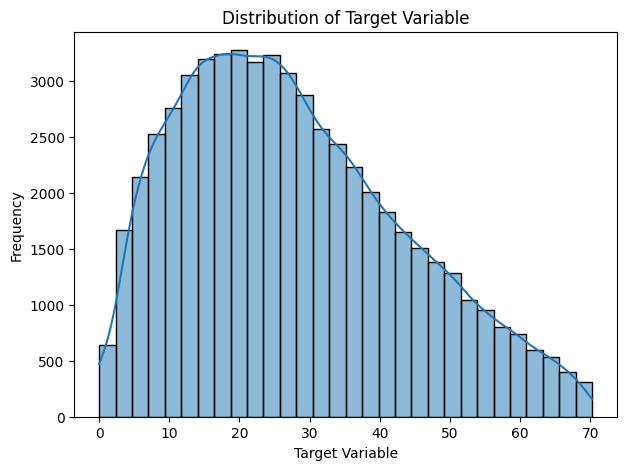

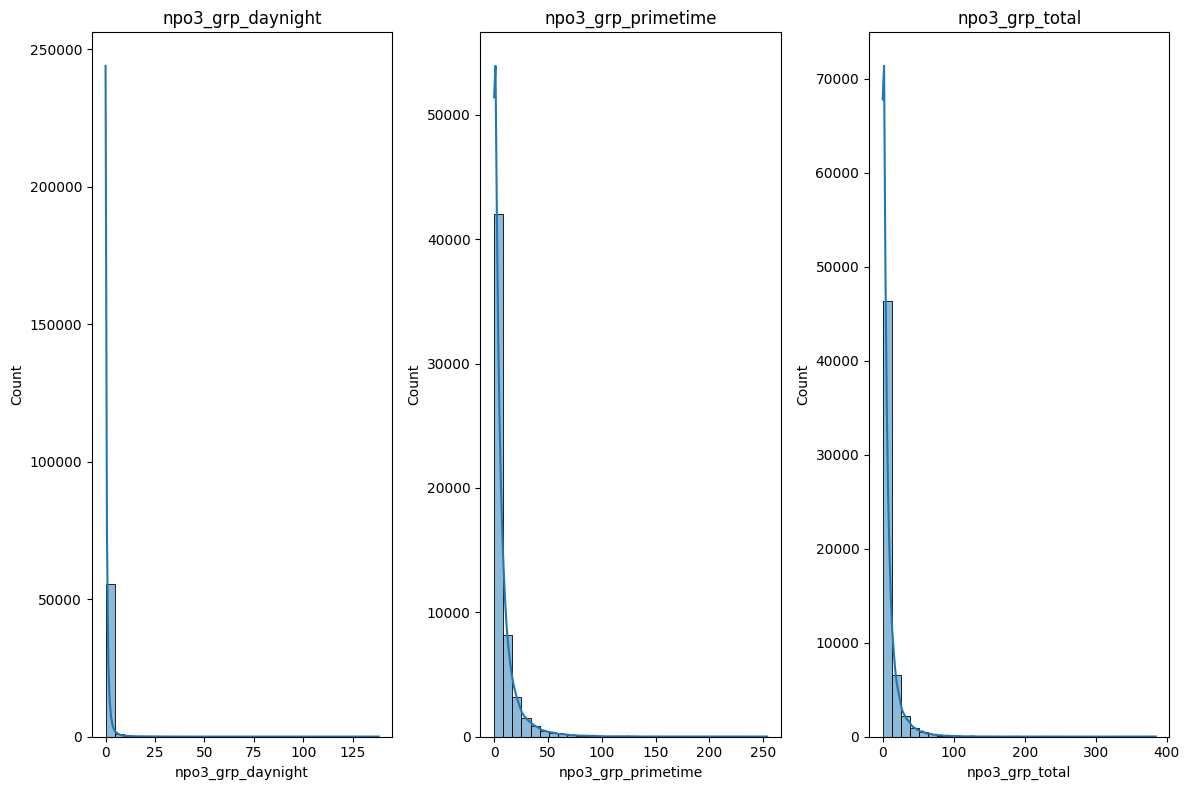

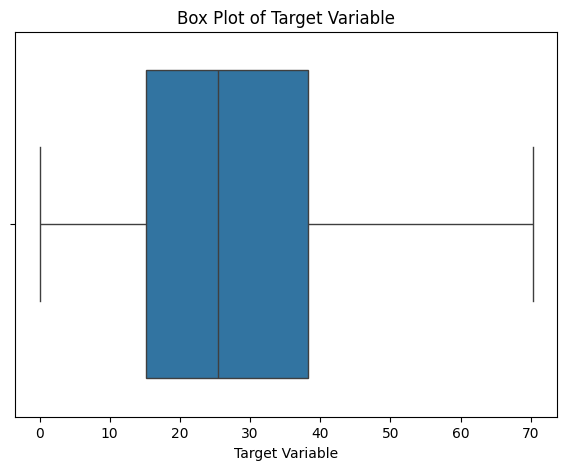

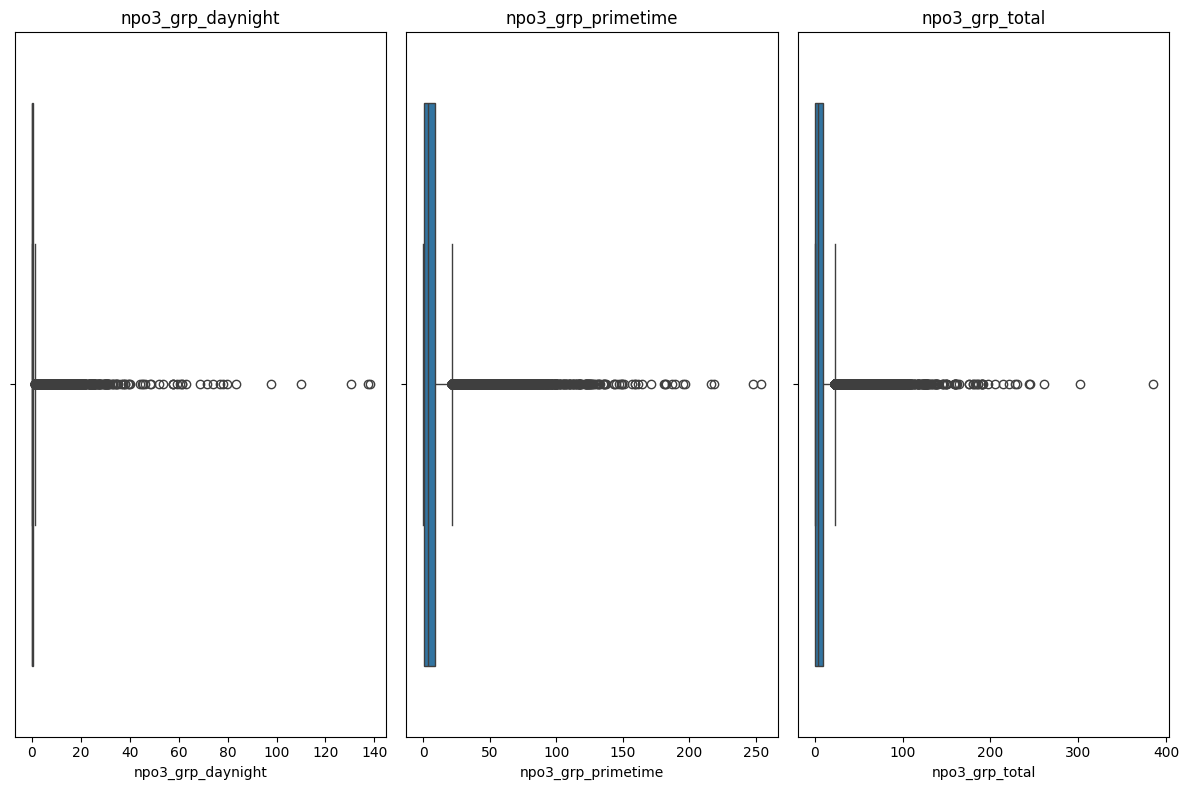

In [14]:
import seaborn as sns
plt.figure(figsize=(7, 5))
sns.histplot(trainer.df['ster_1+_total'], kde=True, bins=30)
plt.title('Distribution of Target Variable')
plt.xlabel('Target Variable')
plt.ylabel('Frequency')
plt.show();

# Boxplot for 'npo3_grp_daynight'
plt.figure(figsize=(12, 8))
plt.subplot(1, 3, 1)  # 1 row, 3 columns, 1st subplot
sns.histplot(trainer.df['npo3_grp_daynight'], kde=True, bins=30)
plt.title('npo3_grp_daynight')

# Boxplot for 'npo3_grp_primetime'
plt.subplot(1, 3, 2)  # 1 row, 3 columns, 2nd subplot
sns.histplot(trainer.df['npo3_grp_primetime'], kde=True, bins=30)
plt.title('npo3_grp_primetime')

# Boxplot for 'npo3_grp_total'
plt.subplot(1, 3, 3)  # 1 row, 3 columns, 3rd subplot
sns.histplot(trainer.df['npo3_grp_total'], kde=True, bins=30)
plt.title('npo3_grp_total')

plt.tight_layout()

plt.figure(figsize=(7, 5))
sns.boxplot(x=trainer.df['ster_1+_total'])
plt.title('Box Plot of Target Variable')
plt.xlabel('Target Variable')
plt.show();

# Boxplot for 'npo3_grp_daynight'
plt.figure(figsize=(12, 8))
plt.subplot(1, 3, 1)  # 1 row, 3 columns, 1st subplot
sns.boxplot(x=trainer.df['npo3_grp_daynight'])
plt.title('npo3_grp_daynight')

# Boxplot for 'npo3_grp_primetime'
plt.subplot(1, 3, 2)  # 1 row, 3 columns, 2nd subplot
sns.boxplot(x=trainer.df['npo3_grp_primetime'])
plt.title('npo3_grp_primetime')

# Boxplot for 'npo3_grp_total'
plt.subplot(1, 3, 3)  # 1 row, 3 columns, 3rd subplot
sns.boxplot(x=trainer.df['npo3_grp_total'])
plt.title('npo3_grp_total')

plt.tight_layout()
plt.show();

In [15]:
# Define bins
df=trainer.df
bin_edges = [0, 1, 2, 3, 4, float('inf')]
df['grp_feature_binned'] = pd.cut(df['npo3_grp_daynight'], bins=bin_edges)

# Count instances in each bin
bin_counts = df['grp_feature_binned'].value_counts().sort_index()

print(bin_counts)

grp_feature_binned
(0.0, 1.0]    18990
(1.0, 2.0]     5155
(2.0, 3.0]     1968
(3.0, 4.0]      908
(4.0, inf]     1770
Name: count, dtype: int64


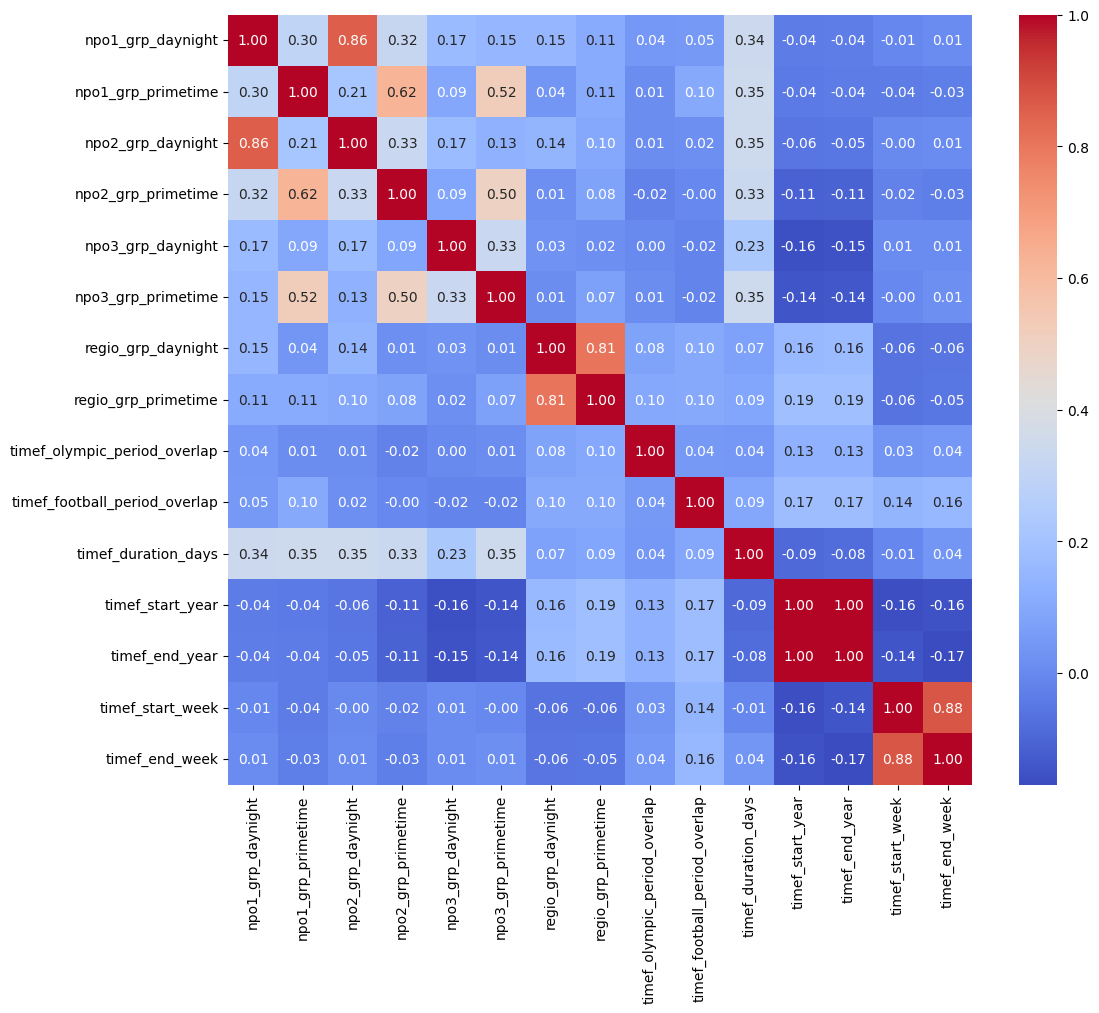

In [16]:
corr_matrix = trainer.df[NUMERICAL_COLS].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.show();

In [25]:
correlation_matrix = trainer.df[['npo1_grp_daynight', 'npo1_grp_primetime', 'npo2_grp_daynight',
                         'npo2_grp_primetime', 'npo3_grp_daynight', 'npo3_grp_primetime',
                         'regio_grp_daynight', 'regio_grp_primetime', 'ster_1+_total']].corr()

correlation_matrix

,npo1_grp_daynight,npo1_grp_primetime,npo2_grp_daynight,npo2_grp_primetime,npo3_grp_daynight,npo3_grp_primetime,regio_grp_daynight,regio_grp_primetime,ster_1+_total
npo1_grp_daynight,1.000000,0.296918,0.855961,0.320380,0.167030,0.153396,0.153961,0.105316,0.501731
npo1_grp_primetime,0.296918,1.000000,0.209715,0.621310,0.093722,0.515822,0.039657,0.108201,0.747213
npo2_grp_daynight,0.855961,0.209715,1.000000,0.331794,0.169385,0.133796,0.143255,0.096978,0.424781
npo2_grp_primetime,0.320380,0.621310,0.331794,1.000000,0.089951,0.498997,0.014950,0.076923,0.606030
npo3_grp_daynight,0.167030,0.093722,0.169385,0.089951,1.000000,0.331907,0.025520,0.015869,0.142363
npo3_grp_primetime,0.153396,0.515822,0.133796,0.498997,0.331907,1.000000,0.011804,0.068588,0.498516
regio_grp_daynight,0.153961,0.039657,0.143255,0.014950,0.025520,0.011804,1.000000,0.807899,0.057156
regio_grp_primetime,0.105316,0.108201,0.096978,0.076923,0.015869,0.068588,0.807899,1.000000,0.076856
ster_1+_total,0.501731,0.747213,0.424781,0.606030,0.142363,0.498516,0.057156,0.076856,1.000000


## Data Check

In [17]:
trainer.split_and_shuffle_data(trainer.df, trainer.val_set_date if trainer.split_type == 'timeseries' else None)
print(trainer.val_set_date, trainer.test_set_date)
trainer.X_train.head(3)
trainer.y_train.head(3)
trainer.X_test.head(3)
trainer.y_test.head(3)


2023-09-01 00:00:00 2024-09-01 00:00:00


,npo1_grp_daynight,npo1_grp_primetime,npo2_grp_daynight,npo2_grp_primetime,npo3_grp_daynight,npo3_grp_primetime,regio_grp_daynight,regio_grp_primetime,timef_olympic_period_overlap,timef_football_period_overlap,timef_duration_days,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_season,timef_end_season,alcohol_kansspelen,new_data
0,14.63,35.21,2.54,4.27,1.03,5.92,0.0,0.0,0,0,27,2018,2018,1,4,Winter,Winter,True,0
1,120.02,35.89,17.41,34.30,1.17,12.47,0.0,0.0,0,0,28,2018,2018,1,4,Winter,Winter,True,0
2,418.17,11.20,34.83,35.98,0.22,29.64,0.0,0.0,0,0,28,2018,2018,1,4,Winter,Winter,True,0


0    37.33
1    56.52
2    56.58
Name: ster_1+_total, dtype: float64

,npo1_grp_daynight,npo1_grp_primetime,npo2_grp_daynight,npo2_grp_primetime,npo3_grp_daynight,npo3_grp_primetime,regio_grp_daynight,regio_grp_primetime,timef_olympic_period_overlap,timef_football_period_overlap,timef_duration_days,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_season,timef_end_season,alcohol_kansspelen,new_data
43317,1.07,6.77,1.03,1.94,0.01,2.09,0.0,0.0,0,0,9,2023,2023,35,36,Autumn,Autumn,False,0
43318,103.48,138.12,8.36,40.54,0.62,15.14,0.0,0.0,0,0,61,2023,2023,35,44,Autumn,Autumn,False,0
43319,0.00,8.35,0.00,3.29,0.00,0.58,0.0,0.0,0,0,6,2023,2023,35,36,Autumn,Autumn,False,0


43317    10.62
43318    54.75
43319     9.63
Name: ster_1+_total, dtype: float64

## Training Model

In [18]:
trainer.grid_search_models()

Fitting 5 folds for each of 1 candidates, totalling 5 fits


  File "c:\git\CampTvNew\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 282, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009070 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11262
[LightGBM] [Info] Number of data points in the train set: 43783, number of used features: 19
[LightGBM] [Info] Start training from score 28.537323
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gai

In [19]:
trainer.models_df

,Model,Parameters,R2 Train,R2 Test,MSE Train,MSE Test,MAE Train,MAE Test
0,LGBM without scaling 25-67,"{'model__boosting_type': 'gbdt', 'model__colsample_bytree': 1.0, 'model__drop_rate': 0.2, 'model__learning_rate': 0.07, 'model__max_bin': 2048, 'model__max_depth': 6, 'model__metric': 'rmse', 'model__min_split_gain': 0.0, 'model__n_estimators': 100, 'model__num_leaves': 41, 'model__objective': 'regression', 'model__reg_alpha': 2.5, 'model__reg_lambda': 2, 'model__seed': 42, 'model__subsample': 0.5, 'model__subsample_freq': 1, 'model__verbose': 1}",0.949916,0.919891,13.142031,17.099844,2.709883,2.888907


## SHAP Visuals

npo1_grp_primetime               8.817302
npo1_grp_daynight                3.751337
timef_duration_days              1.504544
npo3_grp_primetime               1.426207
npo2_grp_primetime               1.299793
timef_start_year                 1.241515
timef_end_week                   0.456035
timef_football_period_overlap    0.325394
npo3_grp_daynight                0.272651
npo2_grp_daynight                0.271001
dtype: float64


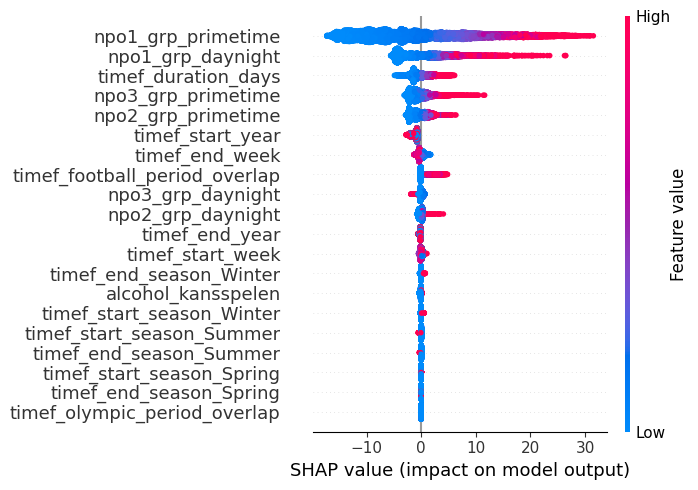

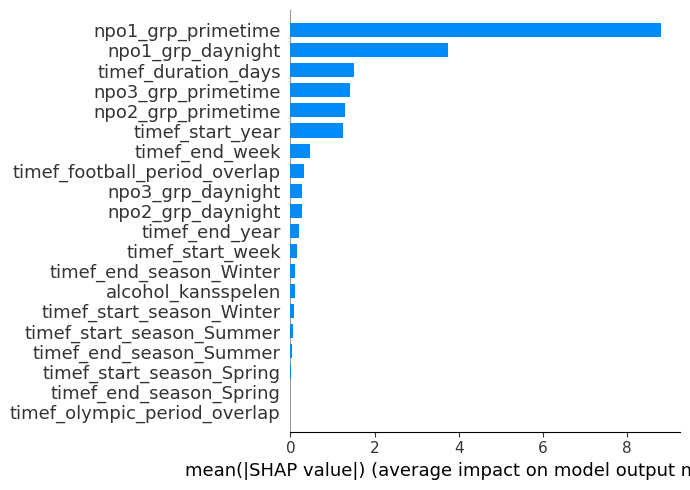

npo1_grp_daynight                   1.07
npo1_grp_primetime                  6.77
npo2_grp_daynight                   1.03
npo2_grp_primetime                  1.94
npo3_grp_daynight                   0.01
npo3_grp_primetime                  2.09
regio_grp_daynight                  0.00
regio_grp_primetime                 0.00
timef_olympic_period_overlap        0.00
timef_football_period_overlap       0.00
timef_duration_days                 9.00
timef_start_year                 2023.00
timef_end_year                   2023.00
timef_start_week                   35.00
timef_end_week                     36.00
timef_start_season_Spring           0.00
timef_start_season_Summer           0.00
timef_start_season_Winter           0.00
timef_end_season_Spring             0.00
timef_end_season_Summer             0.00
timef_end_season_Winter             0.00
alcohol_kansspelen                  0.00
new_data                            0.00
Name: 0, dtype: float64


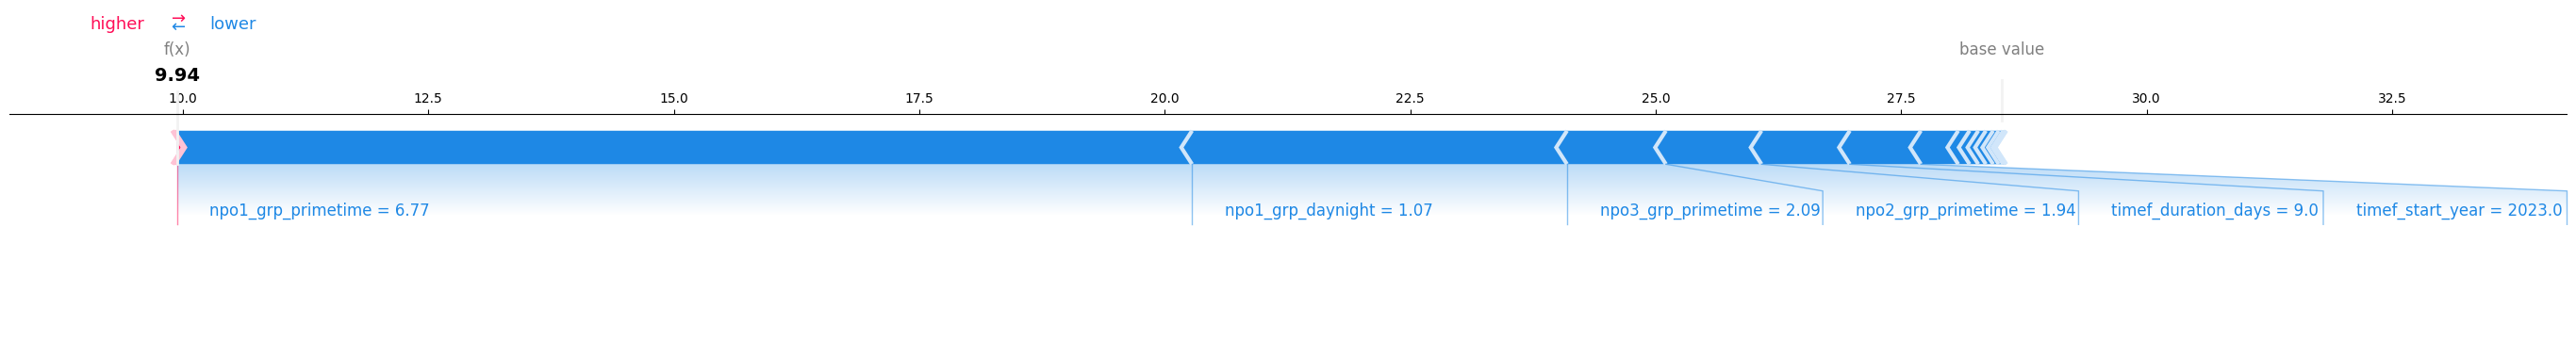

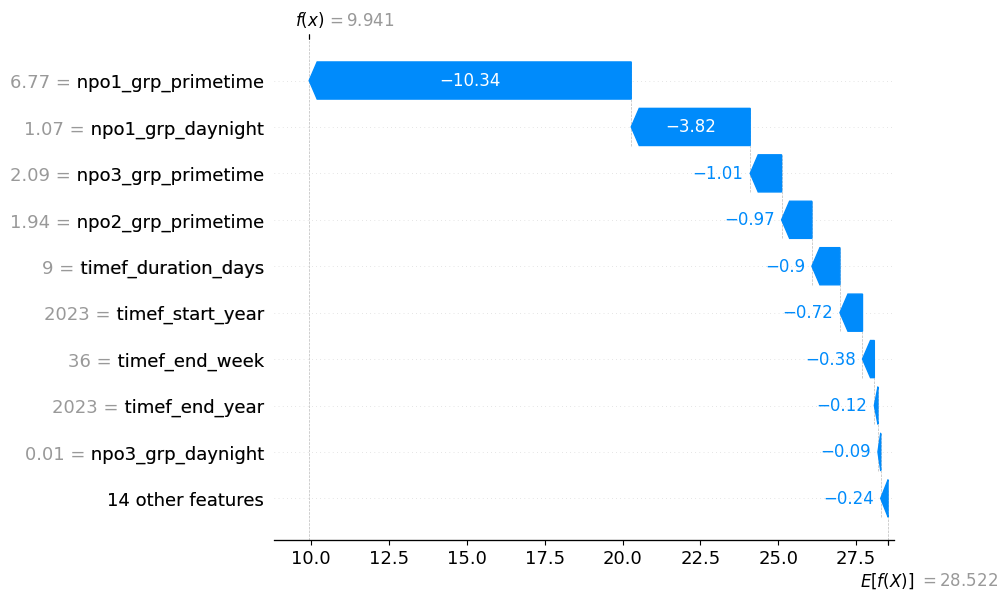

In [29]:
trainer.extract_and_visualize_shap_values(top_n = 10, plot_instance = 0)

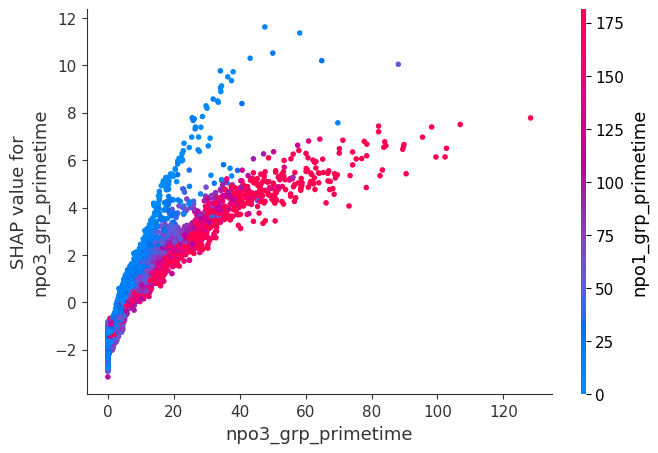

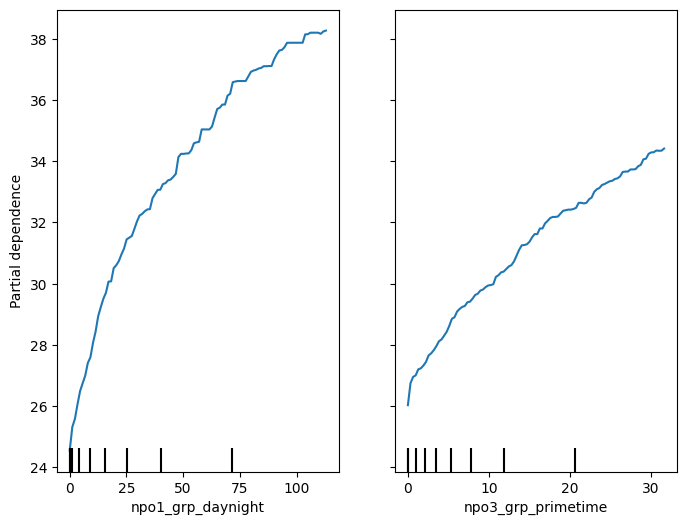

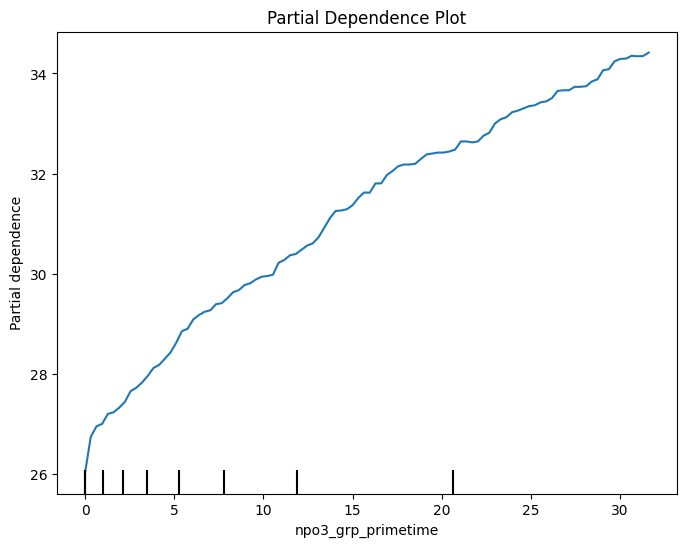

In [26]:
trainer.plot_dependence("npo3_grp_primetime")

In [32]:
from sklearn.inspection import plot_partial_dependence
import matplotlib.pyplot as plt

# Assuming you're using a model from sklearn (e.g., RandomForestRegressor)
plot_partial_dependence(model, X, ['npo1_grp_daynight', 'npo1_grp_primetime'])
plt.show()

ImportError: cannot import name 'plot_partial_dependence' from 'sklearn.inspection' (c:\git\CampTvNew\.venv\Lib\site-packages\sklearn\inspection\__init__.py)

## Predictions

In [30]:
test_period = trainer.test_set_date.date()
print(test_period)

2024-09-01


In [22]:
test_period = trainer.test_set_date.date()

query = f"""
    SELECT  b.flight_id,
            b.target_group,
            f.advertiser,
            f.product,
            f.start_date,
            f.end_date,
            b.campaign_duration,
            b.daypart,
            f.mock_campaign,
            f.alcohol_kansspelen,
            b.total_grp,
            b.ster_grp,
            b.regio_grp,
            b.npo1_grp,
            b.npo2_grp,
            b.npo3_grp,
            b.[ster_1+]
    FROM [dbo].[tv.bereik_ster] b
    LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
    WHERE b.ster_grp > 0 AND target_group = '{trainer.target_group}'
    AND YEAR(f.start_date) = 2024
    AND f.start_date >= '{test_period}'
    ORDER BY start_date
    """

df, results_df = trainer.predict_new_df(query, trainer.target_group, test_period)
trainer.format_excel(results_df, trainer.target_group, test_period)

,npo1_grp_daynight,npo1_grp_primetime,npo2_grp_daynight,npo2_grp_primetime,npo3_grp_daynight,npo3_grp_primetime,regio_grp_daynight,regio_grp_primetime,timef_olympic_period_overlap,timef_football_period_overlap,timef_duration_days,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_season,timef_end_season,alcohol_kansspelen,new_data,prediction,ster_1+_total,residuals
74,41.16,0.00,10.07,8.40,0.00,0.00,1.73,5.75,0,0,15,2024,2024,35,37,Autumn,Autumn,True,1,20.4,24.3,3.8
29,24.89,50.51,4.56,12.36,0.00,8.23,0.00,2.42,0,0,22,2024,2024,35,38,Autumn,Autumn,True,1,36.5,31.7,-4.8
6,11.10,22.16,1.91,1.87,0.40,1.98,0.00,0.18,0,0,20,2024,2024,35,38,Autumn,Autumn,True,1,23.2,20.9,-2.3
3,14.14,60.27,5.39,21.84,4.09,9.49,0.00,0.46,0,0,42,2024,2024,35,41,Autumn,Autumn,True,1,37.1,35.4,-1.7
125,4.97,7.61,0.49,4.21,0.00,4.29,0.00,0.00,0,0,8,2024,2024,35,36,Autumn,Autumn,True,1,14.9,13.7,-1.1
131,0.27,2.91,0.00,6.63,0.00,3.34,0.00,0.45,0,0,12,2024,2024,35,37,Autumn,Autumn,True,1,9.6,11.0,1.4
164,20.39,6.93,2.22,0.00,1.03,0.00,0.00,0.00,0,0,23,2024,2024,35,39,Autumn,Autumn,True,1,18.2,15.0,-3.2
52,199.01,23.52,38.32,29.89,0.00,0.00,1.31,2.86,0,0,20,2024,2024,35,38,Autumn,Autumn,True,1,40.5,43.8,3.3
183,1.83,90.16,0.00,28.46,0.00,22.38,0.00,4.54,0,0,22,2024,2024,35,38,Autumn,Autumn,True,1,41.1,41.7,0.6
151,93.03,0.00,19.35,5.33,0.00,0.00,0.78,0.34,0,0,15,2024,2024,35,37,Autumn,Autumn,True,1,26.5,28.1,1.6


In [ ]:
# single prediction:

# data = {
#     'timef_olympic_period': [0],
#     'timef_football_period': [0],
#     'timef_start_year': timef_start_year,
#     'timef_end_year': timef_end_year,
#     'timef_start_month': timef_start_month,
#     'timef_end_month': timef_end_month,
#     'timef_start_week': timef_start_week,
#     'timef_end_week': timef_end_week,
#     'timef_start_day': timef_start_day,
#     'timef_end_day': timef_end_day,
#     'timef_duration_days': timef_duration_days,
#     'meta_second_spot_duration': [0],
#     'meta_alcohol_adv': [0],
#     'meta_kansspelen_adv': [0],
#     'NPO_1_primetime_GRP': NPO_1_primetime_GRP,
#     'NPO_1_daynight_GRP': NPO_1_daynight_GRP,
#     'NPO_2_primetime_GRP': NPO_2_primetime_GRP,
#     'NPO_2_daynight_GRP': NPO_2_daynight_GRP,
#     'NPO_3_primetime_GRP': NPO_3_primetime_GRP,
#     'NPO_3_daynight_GRP': NPO_3_daynight_GRP
# }

In [ ]:
'''
MODEL_PARAMS = [

    {
        'name': 'LGBM without scaling',
        'model': LGBMRegressor(objective='regression'),
        'params': {
            'model__metric': ['rmse'],
            'model__num_leaves': [41],
            'model__max_depth': [4],
            # 'model__min_data_in_leaf': [20, 50, 80],
            # 'model__min_sum_hessian_in_leaf': [1e-3, 1e-2, 1e-1],
            # 'model__feature_fraction': [0.8, 1.0],
            # 'model__bagging_fraction': [0.8, 1.0],
            # 'model__learning_rate': [0.01, 0.05],
            'model__lambda_l1': [0.1, 0.5],
            'model__lambda_l2': [0.1, 0.5],
            'model__max_bin': [255, 511],
            'model__verbose': [1],
            'model__seed': [42]
        },
        'scaling': 'unscaled'
    },
    # {
    #     'name': 'Gradient Boosting Regressor without scaling',
    #     'model': GradientBoostingRegressor(),
    #     'params': {
    #         'model__learning_rate': [0.03],
    #         'model__max_depth': [5],
    #         'model__max_features': ['sqrt'],
    #         'model__min_samples_leaf': [1],
    #         'model__min_samples_split': [10],
    #         'model__n_estimators': [200],
    #         'model__verbose': [1],
    #         'model__random_state': [42],
    #         'model__subsample': [0.8]
    #     },
    #     'scaling': 'unscaled'
    # },
    # {
    #     'name': 'Hist Gradient Boosting Regressor without scaling',
    #     'model': HistGradientBoostingRegressor(),
    #     'params': {
    #         'model__max_iter': [75, 100, 125],
    #         'model__learning_rate': [0.01, 0.1],
    #         'model__max_depth': [5, 8, 10],
    #         'model__verbose': [1],
    #         'model__random_state': [42]
    #     },
    #     'scaling': 'unscaled'
    # }
]
'''

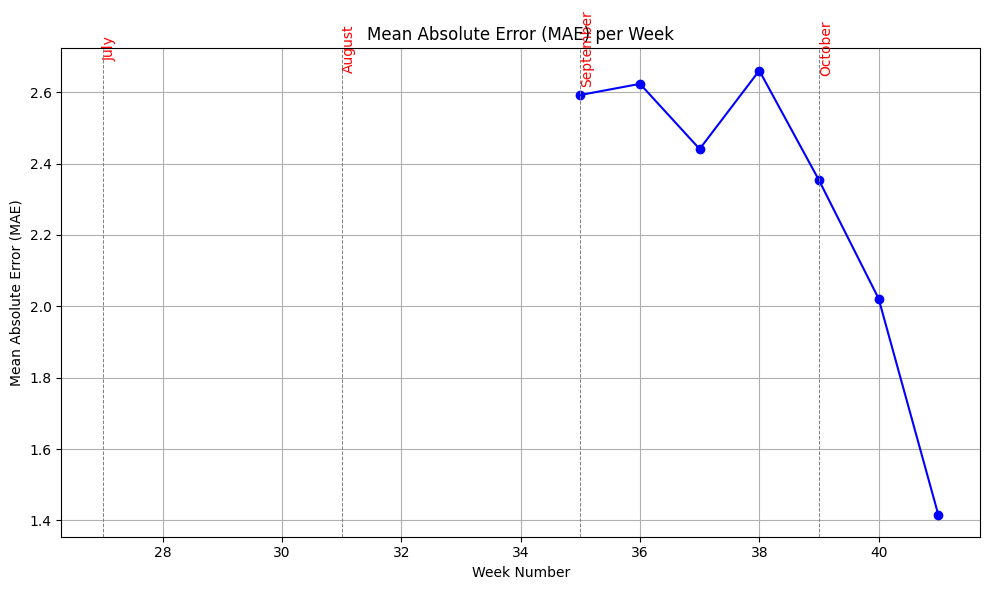

In [27]:
import matplotlib.pyplot as plt

# Load the Excel file
file_path = 'predictions/pred_25-67_2024-09-01.xlsx'  # Replace with your file path
sheet_name = 'Sheet1'  # Replace with the actual sheet name if different
df = pd.read_excel(file_path, sheet_name=sheet_name)

# Calculate the Mean Absolute Error (MAE) per week number
df['absolute_residual'] = df['residuals'].abs()
mean_absolute_error = df.groupby('timef_start_week')['absolute_residual'].mean().reset_index()

# Define week numbers corresponding to the start of each month
# (Example data; replace with your actual week numbers for month starts)
month_starts = {
    27: 'July',
    31: 'August',
    35: 'September',
    39: 'October'

}

# Plot the data
plt.figure(figsize=(10, 6))
plt.plot(mean_absolute_error['timef_start_week'], mean_absolute_error['absolute_residual'], marker='o', linestyle='-', color='b')

# Add vertical lines for each month
for week, month in month_starts.items():
    plt.axvline(x=week, color='gray', linestyle='--', linewidth=0.7)
    plt.text(week, plt.ylim()[1], month, rotation=90, verticalalignment='center', fontsize=10, color='red')

# Customize the graph
plt.title('Mean Absolute Error (MAE) per Week')
plt.xlabel('Week Number')
plt.ylabel('Mean Absolute Error (MAE)')
plt.grid(True)
plt.tight_layout()

# Display the plot
plt.show();